# 01 — Exploratory Data Analysis
UCI Heart Disease dataset (UCI ID 45). This notebook documents data quality, distributions, and relationships before any modelling. **Educational use only — not a clinical diagnostic tool.**


## 1. Setup and data loading

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # make 'src' importable when run from notebooks/

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from src.data import load_dataset

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

RAW = Path.cwd().parent / "data" / "raw" / "heart_disease.csv"
df = load_dataset(RAW)
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


## 2. Dataset overview

In [2]:
print(f"Rows: {df.shape[0]}, Features: {df.shape[1] - 1}, Target: binary (1 = disease present)")
print("\nDtypes:")
print(df.dtypes)
print("\nDescriptive statistics:")
df.describe().T

Rows: 303, Features: 13, Target: binary (1 = disease present)

Dtypes:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
target        int64
dtype: object

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


## 3. Data quality — missing values and duplicates

In [3]:
missing = df.isna().sum().rename("missing_count").to_frame()
missing["missing_pct"] = (missing["missing_count"] / len(df) * 100).round(2)
missing = missing[missing["missing_count"] > 0]
print(missing if len(missing) else "No missing values after cleaning.")
print(f"Duplicate rows: {df.duplicated().sum()}")

      missing_count  missing_pct
ca                4         1.32
thal              2         0.66
Duplicate rows: 0


## 4. Target class balance

/tmp/ipykernel_5742/1747748216.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["no disease (0)", "disease (1)"])


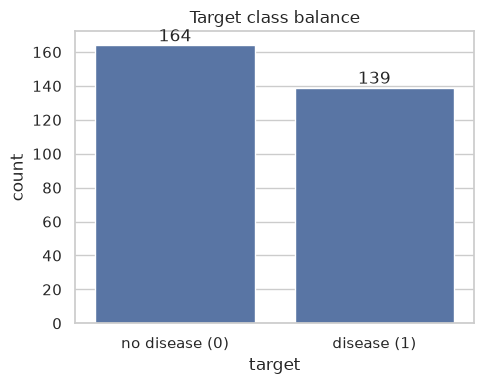

In [4]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="target", ax=ax)
ax.set_xticklabels(["no disease (0)", "disease (1)"])
ax.set_title("Target class balance")
ax.set_ylabel("count")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.savefig("../reports/plots/class_balance.png", dpi=150)
plt.show()

## 5. Feature distributions (histograms)

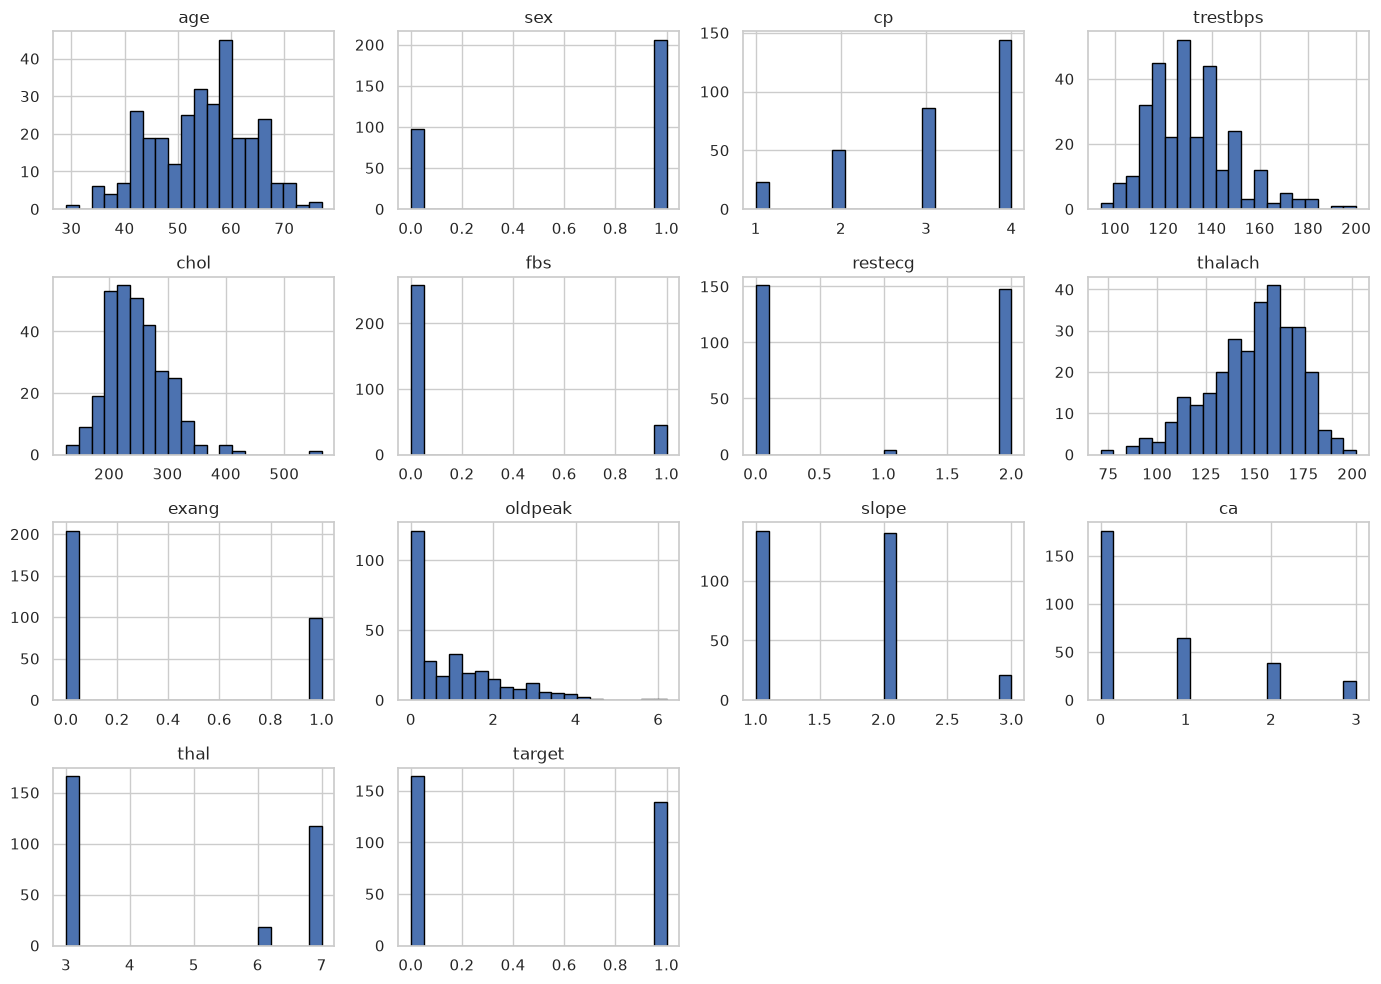

In [5]:
df.hist(figsize=(14, 10), bins=20, edgecolor="black")
plt.tight_layout()
plt.savefig("../reports/plots/feature_histograms.png", dpi=150)
plt.show()

## 6. Correlation analysis

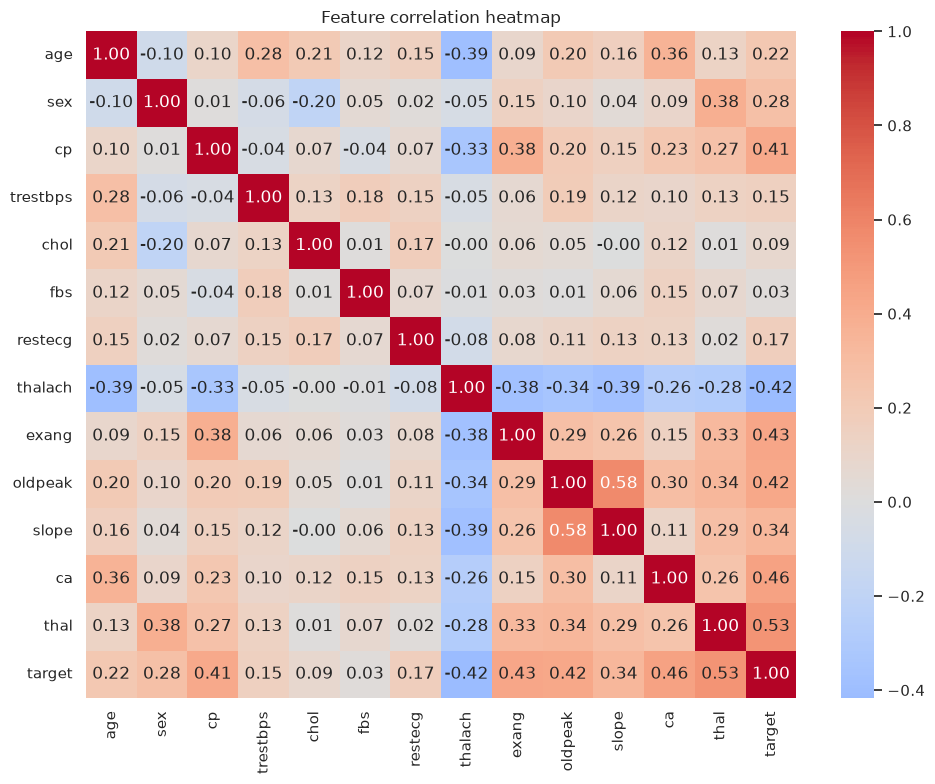

In [6]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature correlation heatmap")
plt.tight_layout()
plt.savefig("../reports/plots/correlation_heatmap.png", dpi=150)
plt.show()

## 7. Key clinical features vs target

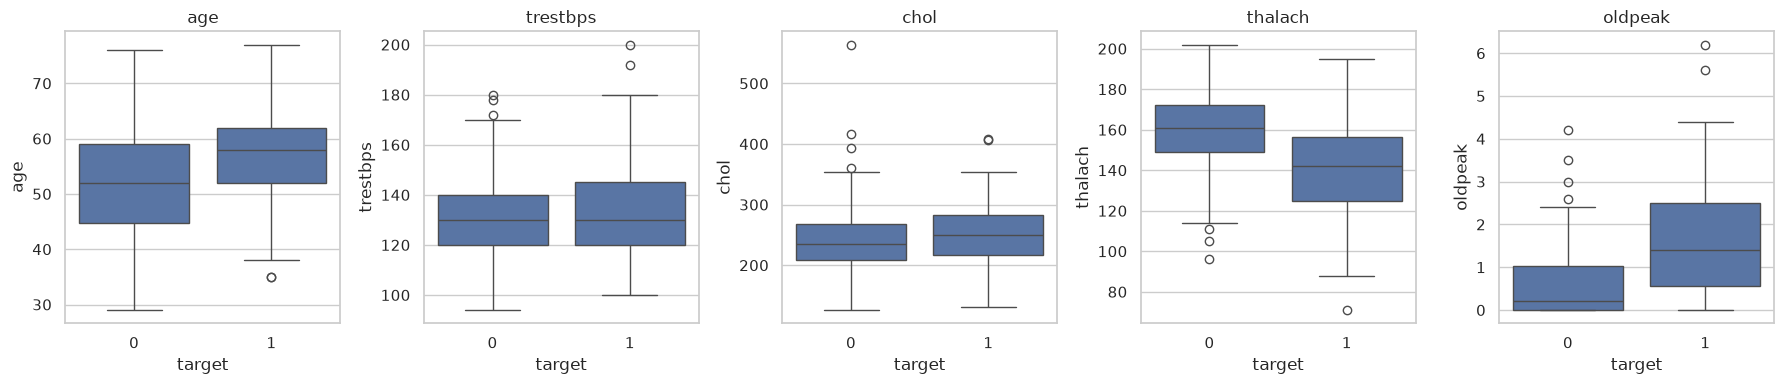

In [7]:
key_features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
fig, axes = plt.subplots(1, len(key_features), figsize=(18, 4))
for ax, feat in zip(axes, key_features):
    sns.boxplot(data=df, x="target", y=feat, ax=ax)
    ax.set_title(feat)
plt.tight_layout()
plt.savefig("../reports/plots/feature_vs_target_boxplots.png", dpi=150)
plt.show()

## 8. Observations

- **Size and quality:** 303 patients and 13 features. Only `ca` (4 rows) and `thal` (2 rows) have missing values and there are no duplicate rows, so I impute inside the pipeline instead of dropping patients.
- **Class balance:** after turning the 0-4 target into disease / no disease, there are 164 patients without disease (54.1%) and 139 with disease (45.9%). That is close enough to balanced that I do not resample; I use stratified splits and look at ROC-AUC as well as accuracy.
- **Strongest signals:** `thal` (r = 0.53), `ca` (0.46), `exang` (0.43), `oldpeak` (0.43) and `cp` (0.41) have the strongest positive correlation with disease. `thalach` (max heart rate) is the only strong negative one (r = -0.42): patients with disease average 139 bpm against 158 bpm for patients without.
- **Chest pain is categorical, not a scale:** `cp` is coded 1-4 and type 4 (asymptomatic) has by far the highest disease rate, 73% of 144 patients, against 18-30% for the other three types. So I treat `cp` as a category and one-hot encode it rather than reading the code as an order.
- **Other clear effects:** exercise-induced angina (`exang` = 1) goes with 77% disease against 31% without it. With `ca` = 0 the disease rate is 26%, rising to 68% at `ca` = 1 and 82-85% at `ca` = 2-3. Men show 55% disease against 26% for women, but the sample is 68% male (206 of 303), which limits how far the model generalises.
- **Distributions:** `oldpeak` (skew 1.27) and `chol` (skew 1.14, maximum 564) are clearly right-skewed with a few extreme values, and `trestbps` is mildly skewed (0.71). `age` is roughly symmetric (mean 54.4). I scale the numeric features with StandardScaler and keep the extreme rows, since the dataset is too small to afford dropping patients.
- **Weak features:** `fbs` (r = 0.03) and `chol` (r = 0.09) are almost unrelated to the target on their own. I leave them in the model but do not expect them to matter much.
- **No collinearity problem:** the numeric features are only weakly correlated with each other (largest |r| = 0.39, between `age` and `thalach`), so multicollinearity is not a concern for logistic regression.
- **Caveat:** these are associations in one small, single-site (Cleveland), male-dominated sample. They are not causal claims and the model is not a diagnostic tool.